# Reference-specific mitigation simulation

In [1]:
from pathlib import Path
import sys

import pandas as pd

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / 'src').exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / 'src'))

from data_preparation import generate_binary_mitigation_data
from mitigation import plot_strategy_effects, run_mitigation_simulation

In [2]:
MEDIATOR_DIM = 1
PENALTY_STRENGTH = 200
TRAINING_OPTIONS = {'n_splits': 5, 'random_state': 9, 'l2': 1e-5}
DR_OPTIONS = {'n_splits': 3, 'random_state': 2}

train = generate_binary_mitigation_data(10_000, mediator_dim=MEDIATOR_DIM, mediator_shift = 0.7, random_state=7)
test = generate_binary_mitigation_data(8_000, mediator_dim=MEDIATOR_DIM, mediator_shift = 0.7, random_state=17)
pd.DataFrame({
    'train': train['data'].describe().loc[['count', 'mean', 'std']].stack(),
    'test': test['data'].describe().loc[['count', 'mean', 'std']].stack(),
})

train         test
count A  10000.000000  8000.000000
      M  10000.000000  8000.000000
      Y  10000.000000  8000.000000
mean  A      0.501700     0.489875
      M     -0.848689    -0.861144
      Y      0.358600     0.351375
std   A      0.500022     0.499929
      M      0.780181     0.785709
      Y      0.479613     0.477430

In [3]:
truth = pd.Series({
    **test['truth']['nested_means'], **test['truth']['effects'],
}, name='population truth')
truth.to_frame().round(4)

,population truth
psi_00,0.1266
psi_01,0.2635
psi_10,0.4328
psi_11,0.5891
nde_m0,0.3062
nde_m1,0.3256
nie_a0,0.1369
nie_a1,0.1563
interaction,0.0194
interaction_via_nie,0.0194


In [4]:
analysis = run_mitigation_simulation(
    train, test, penalty_strength=PENALTY_STRENGTH,
    estimator_kwargs=DR_OPTIONS, **TRAINING_OPTIONS,
)
columns = [
    'nde_m0', 'nde_m1', 'symmetric_nde',
    'nie_a0', 'nie_a1', 'symmetric_nie', 'interaction',
    'total_effect', 'prediction_error', 'converged',
]
analysis['direct'][columns].round(4)

,nde_m0,nde_m1,symmetric_nde,nie_a0,nie_a1,symmetric_nie,interaction,total_effect,prediction_error,converged
model,,,,,,,,,,
No mitigation,0.3049,0.3246,0.3148,0.1254,0.1451,0.1353,0.0198,0.4500,0.4707,True
Penalize NDE at M(0),0.0011,0.0457,0.0234,0.1572,0.2019,0.1796,0.0447,0.2030,0.5306,True
Penalize NDE at M(1),0.1075,0.0012,0.0543,0.2387,0.1324,0.1855,-0.1063,0.2398,0.5158,True
Penalize symmetric NDE,0.0282,-0.0263,0.0010,0.2234,0.1690,0.1962,-0.0544,0.1972,0.5290,True
Penalize both NDEs,0.0008,0.0001,0.0004,0.1913,0.1906,0.1910,-0.0007,0.1914,0.5325,True


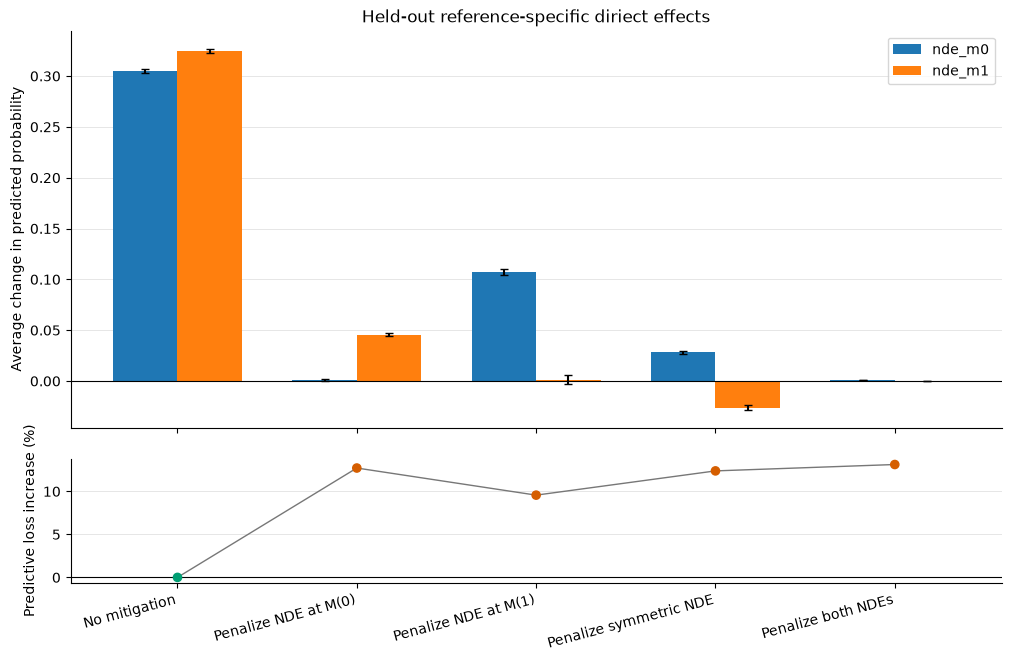

In [5]:
fig = plot_strategy_effects(
    analysis["direct"], ('nde_m0', 'nde_m1'),
    analysis["performance"],
    metric="log_loss",
    title="Held-out reference-specific diriect effects",
    ylabel="Average change in predicted probability",
)

In [6]:
analysis['indirect'][columns].round(4)

,nde_m0,nde_m1,symmetric_nde,nie_a0,nie_a1,symmetric_nie,interaction,total_effect,prediction_error,converged
model,,,,,,,,,,
No mitigation,0.3049,0.3246,0.3148,0.1254,0.1451,0.1353,0.0198,0.4500,0.4707,True
Penalize NIE at A=0,0.3051,0.4491,0.3771,0.0010,0.1451,0.0731,0.1441,0.4502,0.4939,True
Penalize NIE at A=1,0.4496,0.3250,0.3873,0.1253,0.0007,0.0630,-0.1246,0.4503,0.4951,True
Penalize symmetric NIE,0.4722,0.4385,0.4554,0.0184,-0.0153,0.0016,-0.0337,0.4569,0.5163,True
Penalize both NIEs,0.4498,0.4495,0.4496,0.0010,0.0007,0.0009,-0.0003,0.4505,0.5182,True


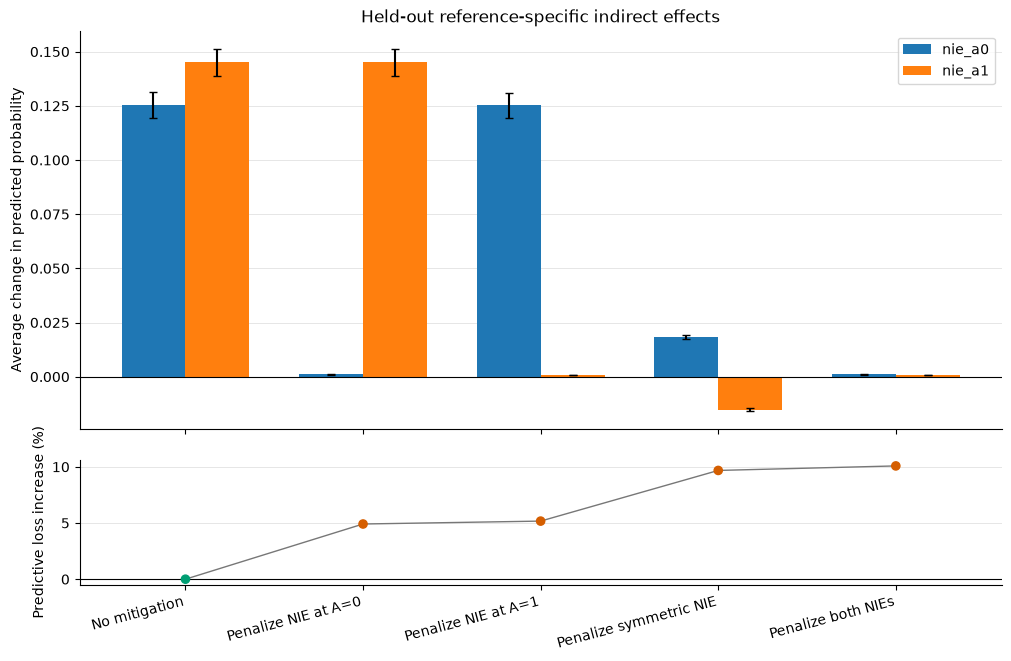

In [7]:
fig = plot_strategy_effects(
    analysis["indirect"], ("nie_a0", "nie_a1"),
    analysis["performance"],
    metric="log_loss",
    title="Held-out reference-specific indirect effects",
    ylabel="Average change in predicted probability",
)


In [8]:
# Focused comparison of the symmetric and both-reference objectives.
comparison_strategies = [
    'No mitigation',
    'Penalize symmetric NDE', 'Penalize both NDEs',
    'Penalize symmetric NIE', 'Penalize both NIEs',
]
effect_comparison = pd.concat([analysis['direct'], analysis['indirect']]).loc[comparison_strategies]
effect_comparison = effect_comparison[~effect_comparison.index.duplicated()]
overall_performance = (
    analysis['performance'].query("scope == 'overall'")
    .set_index('strategy')
)
baseline_loss = overall_performance.loc['No mitigation', 'log_loss']
comparison = effect_comparison[[
    'nde_m0', 'nde_m1', 'symmetric_nde',
    'nie_a0', 'nie_a1', 'symmetric_nie',
]].join(overall_performance[['log_loss']])
comparison['relative_log_loss_increase_pct'] = 100 * (comparison['log_loss'] / baseline_loss - 1)
comparison.round(4)

,nde_m0,nde_m1,symmetric_nde,nie_a0,nie_a1,symmetric_nie,log_loss,relative_log_loss_increase_pct
model,,,,,,,,
No mitigation,0.3049,0.3246,0.3148,0.1254,0.1451,0.1353,0.4707,0.0000
Penalize symmetric NDE,0.0282,-0.0263,0.0010,0.2234,0.1690,0.1962,0.5290,12.3803
Penalize both NDEs,0.0008,0.0001,0.0004,0.1913,0.1906,0.1910,0.5325,13.1218
Penalize symmetric NIE,0.4722,0.4385,0.4554,0.0184,-0.0153,0.0016,0.5163,9.6780
Penalize both NIEs,0.4498,0.4495,0.4496,0.0010,0.0007,0.0009,0.5182,10.0804
